# Лабораторні роботи № 3–4
## Моделювання багатошарових нейронних мереж (`scikit-learn` + `Keras`)

**Формат:** навчальний ноутбук для Google Colab / Jupyter. **Джерело вимог:** файл «ЛБ робота 3-4 Моделювання багатошарових НМ.pdf», с. 1–4.

### Як побудований цей ноутбук

| Блок | Що в ньому є | Чи потрібно змінювати? |
|---|---|---|
| **I-А. Демонстрація `scikit-learn`** | Повністю виконаний приклад класифікації та регресії на **нейтральних** параметрах | **Ні**: запускайте та аналізуйте |
| **I-Б. Індивідуальна робота `scikit-learn`** | Таблиця 28 варіантів, **6 TODO** за постановкою задачі | **Так**: реалізуйте власний варіант |
| **II-А. Демонстрація `Keras`** | Повністю виконаний приклад з **Iris**, якого немає серед варіантів | **Ні**: запускайте та аналізуйте |
| **II-Б. Індивідуальна робота `Keras`** | Таблиця 30 варіантів, **7 TODO** за постановкою задачі | **Так**: працюйте зі своїм датасетом |

**Принцип розмежування:** демонстраційні змінні починаються з `demo_`, індивідуальні — з `student_`. Демонстраційні приклади **не використовують номер варіанта** і не підміняють самостійне виконання. TODO-комірки спочатку містять лише підказки, а не готові розв'язки.

> Частина I: у PDF **6 пунктів** (останній — звіт). Частина II: у PDF **7 пунктів** (останній — звіт). Ця структура відтворена окремо.

## 0. Підготовка середовища

У Google Colab `numpy`, `pandas`, `matplotlib`, `scikit-learn` зазвичай доступні. Для розділу Keras потрібний TensorFlow; якщо його немає, встановіть пакет та перезапустіть середовище виконання.

In [1]:
# Розкоментуйте лише за потреби (напр., у порожньому Jupyter environment):
# %pip install -q numpy pandas matplotlib scikit-learn tensorflow

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.datasets import make_blobs, make_classification, make_regression, load_iris
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import TransformedTargetRegressor
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (
    accuracy_score, classification_report, r2_score,
    mean_absolute_error, mean_squared_error,
    ConfusionMatrixDisplay,
)

DEMO_SEED = 42
np.random.seed(DEMO_SEED)
print('Навчальне середовище готове. NumPy:', np.__version__)

Навчальне середовище готове. NumPy: 2.1.3


---
# ЧАСТИНА I. Багатошарові нейронні мережі засобами `scikit-learn`
## Блок I-А — Нейтральний приклад (готове виконання)

**Ціль прикладу:** побачити всі кроки задачі: генерацію даних, поділ, побудову MLP, навчання, оцінювання, зміну алгоритму й функції активації, порівняння результатів.

**Спеціально використано конфігурацію, якої немає серед 28 варіантів PDF:**

| Параметр | Нейтральна демонстрація |
|---|---|
| Кількість прикладів | `240` (у варіантах: `n = 100 + 2 × номер`, тобто 102–156) |
| Класифікація | `make_blobs`, **4 ознаки**, **5 класів** (у варіантах: 2–3 ознаки, 3–4 класи) |
| Регресія | `make_regression`, **7 ознак**, **1 вихід** (у варіантах: 3–6 ознак) |
| Модель | Два приховані шари `(20, 10)`, `adam`, `relu`, `lr=0.003`, `max_iter=250` |

Ці значення призначені **лише для пояснення техніки**, а не для виконання індивідуального завдання.

### Демонстрація 1. Створення даних і візуалізація

`make_blobs` формує групи прикладів навколо 5 центрів; `make_regression` створює числову ціль на основі ознак. Для відображення беремо **перші дві з чотирьох ознак** — це двовимірна проєкція, тому частина структури може бути неочевидною.

Класифікація: (240, 4) (240,)
Регресія: (240, 7) (240,)


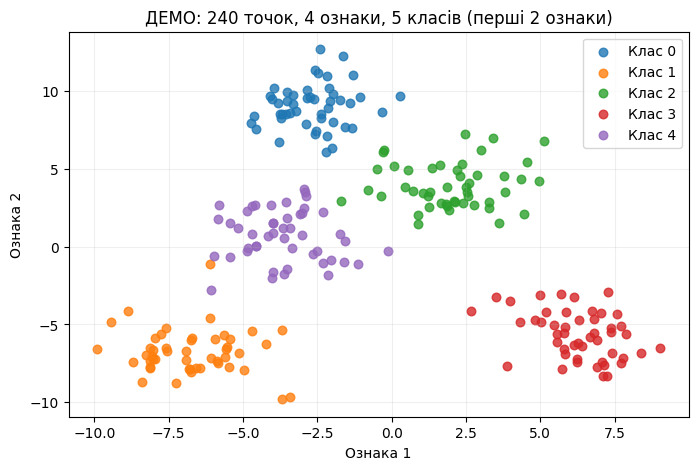

In [3]:
demo_X_cls, demo_y_cls = make_blobs(
    n_samples=240, n_features=4, centers=5, cluster_std=1.5,
    random_state=DEMO_SEED,
)
demo_X_reg, demo_y_reg = make_regression(
    n_samples=240, n_features=7, n_targets=1, noise=10.0,
    random_state=DEMO_SEED,
)

print('Класифікація:', demo_X_cls.shape, demo_y_cls.shape)
print('Регресія:', demo_X_reg.shape, demo_y_reg.shape)

plt.figure(figsize=(8, 5))
for demo_label in np.unique(demo_y_cls):
    demo_mask = demo_y_cls == demo_label
    plt.scatter(
        demo_X_cls[demo_mask, 0], demo_X_cls[demo_mask, 1],
        s=38, alpha=0.8, label=f'Клас {demo_label}',
    )
plt.title('ДЕМО: 240 точок, 4 ознаки, 5 класів (перші 2 ознаки)')
plt.xlabel('Ознака 1')
plt.ylabel('Ознака 2')
plt.legend()
plt.grid(alpha=0.2)
plt.show()

### Демонстрація 2. Поділ train / test (80% / 20%)

Для класифікації `stratify` зберігає приблизно однакові пропорції класів у тренуванні й тестуванні. Після поділу **жоден об'єкт тесту не повинен використовуватися для fit-моделі або масштабувальника**.

In [4]:
demo_Xc_train, demo_Xc_test, demo_yc_train, demo_yc_test = train_test_split(
    demo_X_cls, demo_y_cls, test_size=0.2,
    stratify=demo_y_cls, random_state=DEMO_SEED,
)
demo_Xr_train, demo_Xr_test, demo_yr_train, demo_yr_test = train_test_split(
    demo_X_reg, demo_y_reg, test_size=0.2, random_state=DEMO_SEED,
)

print('Класифікація train / test:', len(demo_Xc_train), len(demo_Xc_test))
print('Регресія train / test:', len(demo_Xr_train), len(demo_Xr_test))

Класифікація train / test: 192 48
Регресія train / test: 192 48


### Демонстрація 3. Створення багатошарових MLP

- `MLPClassifier` прогнозує **клас**.
- `MLPRegressor` прогнозує **неперервне значення**.
- `hidden_layer_sizes=(20, 10)` означає **два приховані шари**: 20 та 10 нейронів.
- `StandardScaler` у `Pipeline` навчається **тільки на train**, що запобігає витоку тестових даних.
- Для регресії `TransformedTargetRegressor` стандартизує ціль під час навчання й повертає прогнози до початкового масштабу. Це особливо корисно, коли масштаби цілі великі.

**Увага:** жоден з цих демонстраційних гіперпараметрів не потрібно автоматично переносити у ваш варіант.

In [5]:
def demo_create_model(task, *, solver, activation, lr, max_iter):
    params = dict(
        hidden_layer_sizes=(20, 10),
        solver=solver,
        activation=activation,
        max_iter=max_iter,
        random_state=DEMO_SEED,
    )
    if solver != 'lbfgs':
        params['learning_rate_init'] = lr

    if task == 'classification':
        return Pipeline([
            ('scaler', StandardScaler()),
            ('mlp', MLPClassifier(**params)),
        ])
    if task == 'regression':
        return TransformedTargetRegressor(
            regressor=Pipeline([
                ('scaler', StandardScaler()),
                ('mlp', MLPRegressor(**params)),
            ]),
            transformer=StandardScaler(),
        )
    raise ValueError('Невідомий тип задачі')

# Для демонстрації обрано гіперпараметри, не задані в жодному варіанті PDF.
demo_classifier = demo_create_model(
    'classification', solver='adam', activation='relu', lr=0.003, max_iter=250,
)
demo_regressor = demo_create_model(
    'regression', solver='adam', activation='relu', lr=0.003, max_iter=250,
)
print('Побудовано моделі: MLPClassifier та MLPRegressor.')

Побудовано моделі: MLPClassifier та MLPRegressor.


### Демонстрація 4. Навчання й метрики на train / test

`fit(X_train, y_train)` підбирає ваги мережі. Для класифікації використаємо **accuracy** та `classification_report`; для регресії — **R², MAE, MSE**. Порівнюємо **обидві** вибірки, щоб оцінити узагальнення моделі. Попередження про незбіжність не означає, що код зламався, але його слід описати у звіті.

In [6]:
with warnings.catch_warnings(record=True) as demo_fit_warnings:
    warnings.simplefilter('always', ConvergenceWarning)
    demo_classifier.fit(demo_Xc_train, demo_yc_train)
    demo_regressor.fit(demo_Xr_train, demo_yr_train)
print('Навчання завершено. Попереджень про збіжність:', len(demo_fit_warnings))


def demo_classifier_metrics(model, label, show_report=False):
    rows = []
    for split, X, y in [
        ('train', demo_Xc_train, demo_yc_train),
        ('test', demo_Xc_test, demo_yc_test),
    ]:
        predictions = model.predict(X)
        rows.append(dict(Модель=label, Вибірка=split, accuracy=accuracy_score(y, predictions)))
        if show_report:
            print(f'\n{label}: classification report, {split}')
            print(classification_report(y, predictions, zero_division=0))
    return pd.DataFrame(rows)


def demo_regressor_metrics(model, label):
    rows = []
    for split, X, y in [
        ('train', demo_Xr_train, demo_yr_train),
        ('test', demo_Xr_test, demo_yr_test),
    ]:
        predictions = model.predict(X)
        rows.append({
            'Модель': label,
            'Вибірка': split,
            'R²': r2_score(y, predictions),
            'MAE': mean_absolute_error(y, predictions),
            'MSE': mean_squared_error(y, predictions),
        })
    return pd.DataFrame(rows)


demo_base_cls_metrics = demo_classifier_metrics(demo_classifier, 'Демо — базова', show_report=True)
demo_base_reg_metrics = demo_regressor_metrics(demo_regressor, 'Демо — базова')
print('\nПоказники класифікації:')
display(demo_base_cls_metrics.round(4))
print('Показники регресії:')
display(demo_base_reg_metrics.round(4))

Навчання завершено. Попереджень про збіжність: 0

Демо — базова: classification report, train
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        38
           1       1.00      1.00      1.00        39
           2       1.00      1.00      1.00        38
           3       1.00      1.00      1.00        38
           4       1.00      1.00      1.00        39

    accuracy                           1.00       192
   macro avg       1.00      1.00      1.00       192
weighted avg       1.00      1.00      1.00       192


Демо — базова: classification report, test
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      1.00      1.00         9
           2       1.00      1.00      1.00        10
           3       1.00      1.00      1.00        10
           4       1.00      1.00      1.00         9

    accuracy                           1.00    

,Модель,Вибірка,accuracy
0,Демо — базова,train,1.0
1,Демо — базова,test,1.0


Показники регресії:


,Модель,Вибірка,R²,MAE,MSE
0,Демо — базова,train,0.9797,17.2279,532.6490
1,Демо — базова,test,0.9454,25.6653,1131.5727


### Демонстрація 5. Інші solver та activation

Для другої конфігурації **одночасно** змінимо `adam → sgd` і `relu → tanh`. Склад тренувальної й тестової вибірок залишиться незмінним. Це ілюструє пункт 4 постановки задачі; порівняння є описовим, бо змінюємо два параметри одночасно.

In [7]:
demo_alt_classifier = demo_create_model(
    'classification', solver='sgd', activation='tanh', lr=0.003, max_iter=250,
)
demo_alt_regressor = demo_create_model(
    'regression', solver='sgd', activation='tanh', lr=0.003, max_iter=250,
)

with warnings.catch_warnings(record=True) as demo_alt_warnings:
    warnings.simplefilter('always', ConvergenceWarning)
    demo_alt_classifier.fit(demo_Xc_train, demo_yc_train)
    demo_alt_regressor.fit(demo_Xr_train, demo_yr_train)
print('Попереджень у другому запуску:', len(demo_alt_warnings))

demo_alt_cls_metrics = demo_classifier_metrics(demo_alt_classifier, 'Демо — sgd+tanh', show_report=True)
demo_alt_reg_metrics = demo_regressor_metrics(demo_alt_regressor, 'Демо — sgd+tanh')

Попереджень у другому запуску: 1

Демо — sgd+tanh: classification report, train
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        38
           1       1.00      1.00      1.00        39
           2       1.00      1.00      1.00        38
           3       1.00      1.00      1.00        38
           4       1.00      1.00      1.00        39

    accuracy                           1.00       192
   macro avg       1.00      1.00      1.00       192
weighted avg       1.00      1.00      1.00       192


Демо — sgd+tanh: classification report, test
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      1.00      1.00         9
           2       1.00      1.00      1.00        10
           3       1.00      1.00      1.00        10
           4       1.00      1.00      1.00         9

    accuracy                           1.00        48
   ma

### Демонстрація 6. Порівняння результатів

Для `accuracy` та `R²` **більше — краще**, для `MAE` й `MSE` **менше — краще**. Зазвичай ключові висновки варто робити за **тестовими** метриками, окремо зазначаючи різницю train–test.

ДЕМО — порівняння класифікації:


,Модель,Вибірка,accuracy
0,Демо — базова,train,1.0
1,Демо — базова,test,1.0
2,Демо — sgd+tanh,train,1.0
3,Демо — sgd+tanh,test,1.0


ДЕМО — порівняння регресії:


,Модель,Вибірка,R²,MAE,MSE
0,Демо — базова,train,0.9797,17.2279,532.6490
1,Демо — базова,test,0.9454,25.6653,1131.5727
2,Демо — sgd+tanh,train,0.9358,32.1577,1686.8332
3,Демо — sgd+tanh,test,0.9275,30.9736,1503.4825


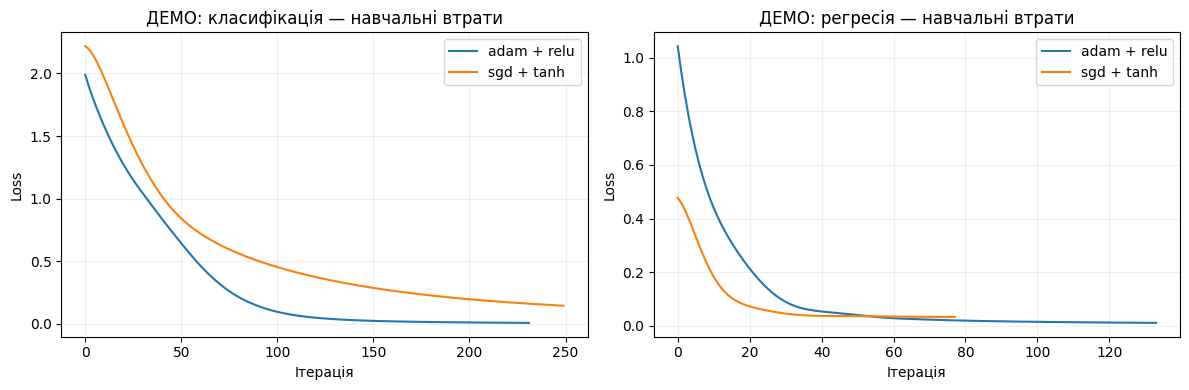

In [8]:
print('ДЕМО — порівняння класифікації:')
display(pd.concat([demo_base_cls_metrics, demo_alt_cls_metrics], ignore_index=True).round(4))
print('ДЕМО — порівняння регресії:')
display(pd.concat([demo_base_reg_metrics, demo_alt_reg_metrics], ignore_index=True).round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, mlp in [
    ('adam + relu', demo_classifier.named_steps['mlp']),
    ('sgd + tanh', demo_alt_classifier.named_steps['mlp']),
]:
    if hasattr(mlp, 'loss_curve_'):
        axes[0].plot(mlp.loss_curve_, label=name)
axes[0].set_title('ДЕМО: класифікація — навчальні втрати')
axes[0].set_xlabel('Ітерація')
axes[0].set_ylabel('Loss')
axes[0].grid(alpha=0.2)
axes[0].legend()
for name, transformer in [
    ('adam + relu', demo_regressor),
    ('sgd + tanh', demo_alt_regressor),
]:
    mlp = transformer.regressor_.named_steps['mlp']
    if hasattr(mlp, 'loss_curve_'):
        axes[1].plot(mlp.loss_curve_, label=name)
axes[1].set_title('ДЕМО: регресія — навчальні втрати')
axes[1].set_xlabel('Ітерація')
axes[1].set_ylabel('Loss')
axes[1].grid(alpha=0.2)
axes[1].legend()
plt.tight_layout()
plt.show()

---
## Блок I-Б — САМОСТІЙНА РОБОТА за індивідуальним варіантом (`scikit-learn`)

**Це окрема частина:** наведені нижче TODO-комірки не використовують `demo_*` змінні. Повторіть показаний вище алгоритм **самостійно**, але за параметрами зі свого рядка таблиці PDF.

**Вимоги з PDF, с. 1–3:** 1) дані + графік + 80/20; 2) дві MLP-моделі; 3) навчання й оцінювання; 4) нові solver + activation; 5) порівняння; 6) звіт.

### Таблиця параметрів 28 варіантів

Наведені значення відповідають таблиці з PDF. Для `lbfgs` швидкість навчання у PDF **не вказана**, тому `learning_rate_init` потрібно опустити. Архітектура прихованих шарів у PDF не задана — оберіть її та обґрунтуйте.

In [9]:
VARIANTS_SKLEARN = {
     1: (2, 3, 4, 1, 'sgd',   'relu',     0.15, 400),
     2: (3, 3, 5, 1, 'adam',  'logistic', 0.15, 350),
     3: (2, 4, 4, 2, 'sgd',   'tanh',     0.15, 450),
     4: (3, 4, 3, 1, 'sgd',   'logistic', 0.15, 500),
     5: (2, 3, 5, 2, 'adam',  'tanh',     0.15, 350),
     6: (2, 3, 4, 2, 'lbfgs', 'tanh',     None, 450),
     7: (3, 3, 5, 2, 'adam',  'relu',     0.20, 450),
     8: (2, 4, 4, 1, 'adam',  'tanh',     0.20, 350),
     9: (3, 4, 3, 2, 'sgd',   'logistic', 0.20, 500),
    10: (2, 3, 5, 1, 'lbfgs', 'logistic', None, 450),
    11: (3, 3, 4, 1, 'adam',  'relu',     0.25, 350),
    12: (2, 4, 5, 2, 'sgd',   'logistic', 0.25, 350),
    13: (3, 4, 4, 1, 'sgd',   'relu',     0.15, 450),
    14: (2, 3, 4, 2, 'lbfgs', 'relu',     None, 350),
    15: (3, 3, 5, 1, 'sgd',   'tanh',     0.25, 400),
    16: (2, 4, 4, 2, 'adam',  'relu',     0.25, 350),
    17: (3, 4, 5, 1, 'sgd',   'logistic', 0.25, 350),
    18: (2, 3, 4, 2, 'adam',  'relu',     0.20, 400),
    19: (3, 3, 4, 1, 'lbfgs', 'logistic', None, 500),
    20: (2, 4, 3, 2, 'adam',  'tanh',     0.25, 500),
    21: (3, 4, 5, 2, 'sgd',   'logistic', 0.15, 450),
    22: (2, 3, 6, 2, 'lbfgs', 'tanh',     None, 300),
    23: (2, 4, 4, 2, 'sgd',   'relu',     0.20, 500),
    24: (3, 4, 5, 1, 'adam',  'logistic', 0.15, 450),
    25: (3, 3, 5, 2, 'lbfgs', 'relu',     None, 300),
    26: (3, 4, 5, 1, 'sgd',   'tanh',     0.15, 350),
    27: (2, 3, 4, 1, 'adam',  'relu',     0.25, 500),
    28: (2, 4, 3, 1, 'sgd',   'logistic', 0.25, 450),
}

student_sklearn_columns = [
    'Ознаки класифікації', 'Класи', 'Ознаки регресії', 'Цілі регресії',
    'solver', 'activation', 'learning_rate_init', 'max_iter',
]
student_sklearn_table = pd.DataFrame.from_dict(
    VARIANTS_SKLEARN, orient='index', columns=student_sklearn_columns,
)
student_sklearn_table.index.name = 'Варіант'
print('Довідник індивідуальних параметрів. Не є виконанням TODO.')
display(student_sklearn_table)

Довідник індивідуальних параметрів. Не є виконанням TODO.


,Ознаки класифікації,Класи,Ознаки регресії,Цілі регресії,solver,activation,learning_rate_init,max_iter
Варіант,,,,,,,,
1,2,3,4,1,sgd,relu,0.15,400
2,3,3,5,1,adam,logistic,0.15,350
3,2,4,4,2,sgd,tanh,0.15,450
4,3,4,3,1,sgd,logistic,0.15,500
5,2,3,5,2,adam,tanh,0.15,350
6,2,3,4,2,lbfgs,tanh,NaN,450
7,3,3,5,2,adam,relu,0.20,450
8,2,4,4,1,adam,tanh,0.20,350
9,3,4,3,2,sgd,logistic,0.20,500


### Вибір номера варіанта

Змініть `STUDENT_SKLEARN_VARIANT` **лише для власної роботи**. Це ніяк не вплине на нейтральні приклади попереднього блоку.

In [10]:
STUDENT_SKLEARN_VARIANT = 1  # TODO: установіть свій номер (1..28)
assert STUDENT_SKLEARN_VARIANT in VARIANTS_SKLEARN

student_sklearn_config = dict(zip(
    student_sklearn_columns, VARIANTS_SKLEARN[STUDENT_SKLEARN_VARIANT],
))
student_expected_n = 100 + 2 * STUDENT_SKLEARN_VARIANT
print('Ваш номер:', STUDENT_SKLEARN_VARIANT, '→ кількість точок:', student_expected_n)
display(student_sklearn_table.loc[[STUDENT_SKLEARN_VARIANT]])

Ваш номер: 1 → кількість точок: 102


,Ознаки класифікації,Класи,Ознаки регресії,Цілі регресії,solver,activation,learning_rate_init,max_iter
Варіант,,,,,,,,
1,2,3,4,1,sgd,relu,0.15,400


### 📝 TODO 1/6 — Створити дані для свого варіанта

**Пункт 1 PDF.** Самостійно:

- [ ] Обчисліть `n = 100 + 2 × номер_варіанта`.
- [ ] Згенеруйте класифікаційний набір: **непарні** варіанти — `make_blobs`, **парні** — `make_classification`.
- [ ] Укажіть **точну кількість ознак і класів** із `student_sklearn_config`.
- [ ] Згенеруйте дані для регресії через `make_regression` із потрібним числом ознак і цілей.
- [ ] Візуалізуйте розподіл класів; для 3 ознак можна показати проєкцію на перші 2.
- [ ] Розбийте **кожний набір** на 80% train / 20% test (для класифікації бажано `stratify`).

**Важлива підказка:** для `make_classification` із малою кількістю ознак можуть знадобитися `n_redundant=0`, `n_repeated=0`, `n_clusters_per_class=1` (це технічні допоміжні параметри, не гіперпараметри варіанта). Назвіть вихідні масиви `student_Xc_train`, `student_Xc_test`, `student_yc_train`, `student_yc_test` та аналогічно `student_Xr_*`, `student_yr_*`.

In [11]:
# TODO 1/6 — ВАШ КОД (не копіюйте demo_* дані)
# 1. student_n = ...
# 2. Якщо STUDENT_SKLEARN_VARIANT % 2 == 1:
#        student_X_cls, student_y_cls = make_blobs(...)
#    інакше:
#        student_X_cls, student_y_cls = make_classification(...)
# 3. student_X_reg, student_y_reg = make_regression(...)
# 4. Побудуйте scatter-графік класів.
# 5. student_Xc_train, student_Xc_test, student_yc_train, student_yc_test = ...
# 6. student_Xr_train, student_Xr_test, student_yr_train, student_yr_test = ...

# ВАШ КОД НИЖЧЕ:

### 📝 TODO 2/6 — Побудувати дві нейромережі

**Пункт 2 PDF.** Створіть окремі моделі `MLPClassifier` та `MLPRegressor` із початковими параметрами свого варіанта: `solver`, `activation`, `max_iter`, `learning_rate_init` (за наявності). Самостійно виберіть **не менш як два приховані шари**, наприклад записані в кортежі `hidden_layer_sizes`, і зафіксуйте цей вибір у звіті.

Масштабуйте ознаки коректно: статистики scaler отримуємо тільки з train. Для великих числових цілей регресії можна використати `TransformedTargetRegressor`, як у демонстрації. Для `lbfgs` не передавайте `learning_rate_init` (він не використовується). Створіть `student_clf` і `student_reg`.

In [12]:
# TODO 2/6 — ВАШ КОД
# Дістаньте solver, activation, max_iter, learning_rate_init
# з student_sklearn_config (параметри у PDF змінювати не можна).
# За допомогою Pipeline/StandardScaler створіть:
# student_clf = ...
# student_reg = ...
# Приклади назв класів: MLPClassifier, MLPRegressor,
# Pipeline, StandardScaler, TransformedTargetRegressor.

# ВАШ КОД НИЖЧЕ:

### 📝 TODO 3/6 — Навчити й оцінити моделі

**Пункт 3 PDF.** Навчіть `student_clf` і `student_reg` **лише на train**. Побудуйте прогнози для train і test. Обов'язково виведіть:

- **Класифікація:** `accuracy` і `classification_report` **на train та test**.
- **Регресія:** `R²`, `MAE`, `MSE` **на train та test**.

Створіть окремі таблиці результатів `student_cls_base_results`, `student_reg_base_results`; порівняйте якість на різних вибірках. Для регресії з кількома цільовими змінними можна показати як середні значення, так і метрики окремо для кожної цілі.

In [13]:
# TODO 3/6 — ВАШ КОД
# student_clf.fit(student_Xc_train, student_yc_train)
# student_reg.fit(student_Xr_train, student_yr_train)
# Порахуйте train/test accuracy + classification_report,
# train/test R2, MAE, MSE для регресії.
# student_cls_base_results = ...
# student_reg_base_results = ...

# ВАШ КОД НИЖЧЕ:

### 📝 TODO 4/6 — Змінити solver та activation

**Пункт 4 PDF.** Оберіть **інший** `solver` (`sgd`, `adam` або `lbfgs`) та **іншу** `activation` (`relu`, `logistic`, `tanh`), порівняно з початковими параметрами свого варіанта. Побудуйте і заново навчіть `student_clf_alt`, `student_reg_alt`.

Для порівняння залишайте однаковими набори train/test та архітектуру. Якщо перейти з `lbfgs` до `sgd`/`adam`, підберіть **нову** швидкість навчання самостійно й зазначте в звіті, що в PDF її для `lbfgs` не задано.

In [14]:
# TODO 4/6 — ВАШ КОД
# student_alt_solver = ...       # має відрізнятися від початкового
# student_alt_activation = ...  # має відрізнятися від початкової
# student_clf_alt = ...
# student_reg_alt = ...
# student_clf_alt.fit(...)
# student_reg_alt.fit(...)
# Порахуйте на тих самих наборах train/test такі самі метрики.
# student_cls_alt_results = ...
# student_reg_alt_results = ...

# ВАШ КОД НИЖЧЕ:

### 📝 TODO 5/6 — Порівняти результати

**Пункт 5 PDF.** Зіставте **«до» / «після»** в таблицях для обох задач на train і test. Поясніть, яка конфігурація краща для **класифікації** за accuracy та для **регресії** за R² / MAE / MSE. Зазначте ознаки можливого перенавчання, похибки та попередження про збіжність, якщо вони були.

In [15]:
# TODO 5/6 — ВАШ КОД
# Складіть таблиці порівняння:
# pd.concat([student_cls_base_results, student_cls_alt_results])
# pd.concat([student_reg_base_results, student_reg_alt_results])
# За бажанням побудуйте діаграми відмінностей метрик.

# ВАШ КОД НИЖЧЕ:

### 📝 TODO 6/6 — Підготувати звіт

**Пункт 6 PDF.** У звіті повинні бути: **титульна сторінка**, **постановка задачі**, **лістинг коду**, **результати** та **висновок**. Зберіть графік набору класів, параметри моделей, метрики train/test, порівняльні таблиці та пояснення, який вплив мали `solver` / `activation`.

Заповніть власними числовими результатами (не значеннями з демонстрації):

| Що потрібно зафіксувати | Ваш результат |
|---|---|
| Номер варіанта; `n`; генератор класифікації | **TODO:** ... |
| Кількість ознак, класів, цілей | **TODO:** ... |
| Початкові й альтернативні solver/activation | **TODO:** ... |
| Test accuracy «до → після» | **TODO:** ... |
| Test R² / MAE / MSE «до → після» | **TODO:** ... |
| Чи є різниця між train / test; підсумковий висновок | **TODO:** ... |

**TODO (ваш письмовий висновок, 4–7 речень):** ...

---
# ЧАСТИНА II. Багатошарові нейронні мережі засобами `Keras`
## Блок II-А — Нейтральний приклад (готове виконання)

**Демонстраційний датасет: `Iris` (`load_iris()`)**. Його **немає** у списку 6 датасетів, запропонованих у PDF для 30 варіантів Keras. Цей розділ показує підготовку даних, побудову `Sequential(Dense)`, навчання, криві втрат, прогнози, `classification_report`, `confusion matrix` та експерименти з архітектурою.

> Якщо `tensorflow` не встановлено, цей демонстраційний розділ пропускає виконання навчання й пояснює, як установити пакет. TODO-комірки залишаються доступними.

### Демонстрація 1. Підготовка Iris та розбиття на train / validation / test

Датасет містить **4 числові ознаки і 3 класи**. Зовнішній тестовий набір (20%) використовуємо для фінальної перевірки. Із решти train додатково виділяємо validation, щоб порівнювати архітектури **без підбору під test**. Дані масштабуємо, навчаючи `StandardScaler` лише на train.

In [16]:
try:
    import tensorflow as tf
    KERAS_DEMO_AVAILABLE = True
    print('TensorFlow:', tf.__version__)
except ImportError:
    tf = None
    KERAS_DEMO_AVAILABLE = False
    print('TensorFlow не встановлено. У Google Colab або локально виконайте:')
    print('    %pip install tensorflow')
    print('Після інсталяції перезапустіть середовище та запустіть ноутбук з початку.')

# Датасет Iris — лише для прикладу; індивідуальний датасет вибирають далі.
demo_iris = load_iris()
demo_keras_X_all = demo_iris.data.astype('float32')
demo_keras_y_all = demo_iris.target.astype('int32')
demo_keras_names = [str(x) for x in demo_iris.target_names]

demo_keras_X_remaining, demo_keras_X_test_raw, demo_keras_y_remaining, demo_keras_y_test = train_test_split(
    demo_keras_X_all, demo_keras_y_all, test_size=0.20,
    stratify=demo_keras_y_all, random_state=DEMO_SEED,
)
demo_keras_X_train_raw, demo_keras_X_val_raw, demo_keras_y_train, demo_keras_y_val = train_test_split(
    demo_keras_X_remaining, demo_keras_y_remaining, test_size=0.20,
    stratify=demo_keras_y_remaining, random_state=DEMO_SEED,
)
demo_keras_scaler = StandardScaler()
demo_keras_X_train = demo_keras_scaler.fit_transform(demo_keras_X_train_raw).astype('float32')
demo_keras_X_val = demo_keras_scaler.transform(demo_keras_X_val_raw).astype('float32')
demo_keras_X_test = demo_keras_scaler.transform(demo_keras_X_test_raw).astype('float32')

print('ДЕМО Iris: train / val / test =', len(demo_keras_X_train), len(demo_keras_X_val), len(demo_keras_X_test))
print('Назви класів:', demo_keras_names)

TensorFlow: 2.21.0
ДЕМО Iris: train / val / test = 96 24 30
Назви класів: ['setosa', 'versicolor', 'virginica']


### Демонстрація 2. Повнозв'язна модель у Keras

Мережа `Dense(24, relu) → Dense(12, relu) → Dense(3, softmax)` має два приховані шари. Вихідний шар `softmax` повертає імовірності трьох класів. `sparse_categorical_crossentropy` підходить, оскільки правильні мітки — цілі числа 0, 1, 2.

Ініціалізація ваг випадкова, тому для повторюваності виставляємо seed. Навчальні параметри цього прикладу **не є умовами будь-якого індивідуального варіанта**.

In [17]:
if KERAS_DEMO_AVAILABLE:
    def demo_keras_build(hidden=(24, 12), activation='relu', optimizer='adam'):
        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(DEMO_SEED)
        model = tf.keras.Sequential(name='iris_demo_classifier')
        model.add(tf.keras.layers.Input(shape=(demo_keras_X_train.shape[1],)))
        for units in hidden:
            model.add(tf.keras.layers.Dense(units, activation=activation))
        model.add(tf.keras.layers.Dense(3, activation='softmax'))
        model.compile(
            optimizer=optimizer,
            loss='sparse_categorical_crossentropy',
            metrics=['accuracy'],
        )
        return model

    demo_keras_base = demo_keras_build()
    demo_keras_base.summary()
else:
    print('Пропущено створення Keras-моделі: потрібен tensorflow.')

Model: "iris_demo_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 24)             │           120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 12)             │           300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            39 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 459 (1.79 KB)

 Trainable params: 459 (1.79 KB)

 Non-trainable params: 0 (0.00 B)

### Демонстрація 3. Навчання та криві втрат

Метод `fit()` повертає об'єкт `History` із покроковими значеннями `loss`, `val_loss`, `accuracy`. Якщо навчальні втрати зменшуються, а `val_loss` починає зростати, це може свідчити про перенавчання. В навчальному прикладі показуємо train і validation криві.

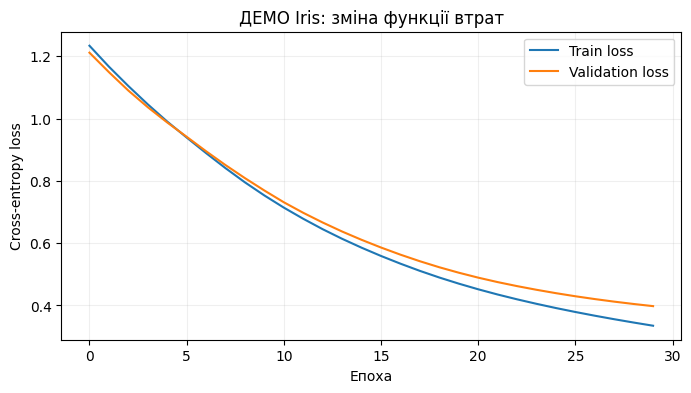

In [18]:
if KERAS_DEMO_AVAILABLE:
    demo_keras_history = demo_keras_base.fit(
        demo_keras_X_train, demo_keras_y_train,
        validation_data=(demo_keras_X_val, demo_keras_y_val),
        epochs=30, batch_size=16, verbose=0,
    )
    plt.figure(figsize=(8, 4))
    plt.plot(demo_keras_history.history['loss'], label='Train loss')
    plt.plot(demo_keras_history.history['val_loss'], label='Validation loss')
    plt.title('ДЕМО Iris: зміна функції втрат')
    plt.xlabel('Епоха')
    plt.ylabel('Cross-entropy loss')
    plt.legend()
    plt.grid(alpha=0.2)
    plt.show()
else:
    print('Пропущено навчання: потрібен tensorflow.')

### Демонстрація 4. Прогнози, classification report та confusion matrix

`predict` повертає розподіли ймовірностей, `argmax(axis=1)` — номер передбаченого класу. Матриця помилок показує, які класи сплутала мережа (рядки — істинні, стовпці — прогнозовані).

Імовірності (перші 3 записи):
 [[0.949 0.041 0.01 ]
 [0.046 0.228 0.726]
 [0.172 0.755 0.073]]
ДЕМО classification report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      0.50      0.62        10
   virginica       0.64      0.90      0.75        10

    accuracy                           0.80        30
   macro avg       0.83      0.80      0.79        30
weighted avg       0.83      0.80      0.79        30



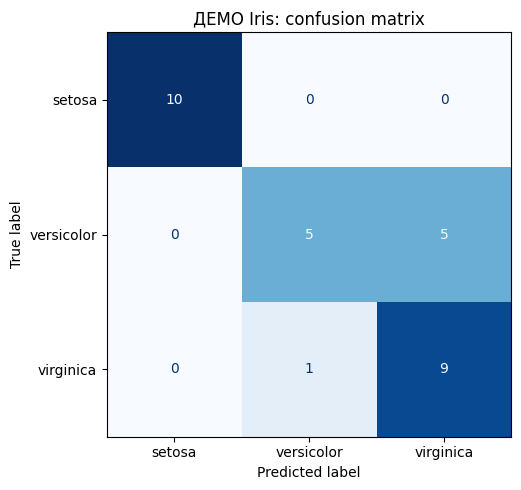

In [19]:
if KERAS_DEMO_AVAILABLE:
    demo_keras_probabilities = demo_keras_base.predict(demo_keras_X_test, verbose=0)
    demo_keras_predictions = np.argmax(demo_keras_probabilities, axis=1)
    print('Імовірності (перші 3 записи):\n', demo_keras_probabilities[:3].round(3))
    print('ДЕМО classification report:')
    print(classification_report(
        demo_keras_y_test, demo_keras_predictions,
        labels=[0, 1, 2], target_names=demo_keras_names, zero_division=0,
    ))
    fig, ax = plt.subplots(figsize=(6, 5))
    ConfusionMatrixDisplay.from_predictions(
        demo_keras_y_test, demo_keras_predictions,
        labels=[0, 1, 2], display_labels=demo_keras_names,
        cmap='Blues', ax=ax, colorbar=False,
    )
    ax.set_title('ДЕМО Iris: confusion matrix')
    plt.tight_layout()
    plt.show()
else:
    print('Пропущено Keras-оцінювання: потрібен tensorflow.')

### Демонстрація 5. Експерименти з Keras

Змінюємо **по одному** параметру відносно початкової моделі, зберігаючи однакові дані та кількість епох:

| Експеримент | Кількість нейронів | Функція активації | Оптимізатор |
|---|---|---|---|
| Базова | `(24, 12)` | `relu` | `adam` |
| Більше нейронів | `(48, 24)` | `relu` | `adam` |
| Інша активація | `(24, 12)` | `tanh` | `adam` |
| Інший оптимізатор | `(24, 12)` | `relu` | `sgd` |

**Критерій порівняння:** `validation loss`, не `test loss`. Тестовий набір використовуємо тільки для фінального висновку щодо вибраної конфігурації.

,Модель,Архітектура,Активація,Оптимізатор,Train loss,Validation loss,Validation accuracy
0,Базова,"(24, 12)",relu,adam,0.3289,0.3977,0.7917
1,Більше нейронів,"(48, 24)",relu,adam,0.1883,0.2681,0.8333
2,Інша активація,"(24, 12)",tanh,adam,0.2805,0.3761,0.7917
3,Інший оптимізатор,"(24, 12)",relu,sgd,0.5171,0.5511,0.7917


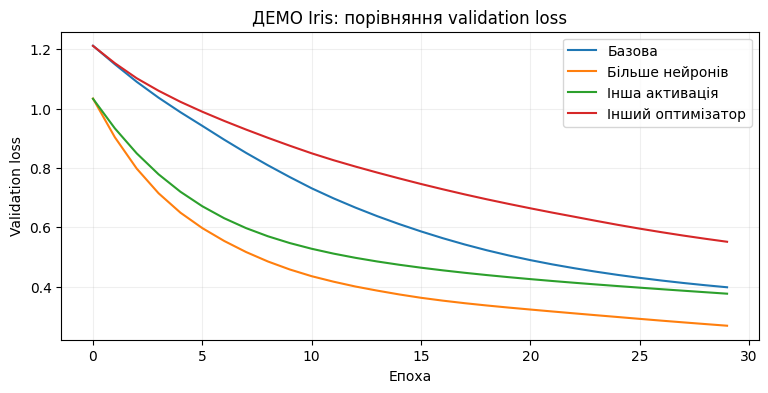

Найкраща за validation loss: Більше нейронів
Фінальна оцінка на test: loss=0.2662, accuracy=0.8667


In [20]:
if KERAS_DEMO_AVAILABLE:
    demo_keras_experiments = [
        ('Базова', (24, 12), 'relu', 'adam'),
        ('Більше нейронів', (48, 24), 'relu', 'adam'),
        ('Інша активація', (24, 12), 'tanh', 'adam'),
        ('Інший оптимізатор', (24, 12), 'relu', 'sgd'),
    ]
    demo_keras_models = {'Базова': demo_keras_base}
    demo_keras_histories = {'Базова': demo_keras_history}
    demo_keras_rows = []

    for name, hidden, activation, optimizer in demo_keras_experiments:
        if name == 'Базова':
            model, history = demo_keras_base, demo_keras_history
        else:
            model = demo_keras_build(hidden=hidden, activation=activation, optimizer=optimizer)
            history = model.fit(
                demo_keras_X_train, demo_keras_y_train,
                validation_data=(demo_keras_X_val, demo_keras_y_val),
                epochs=30, batch_size=16, verbose=0,
            )
            demo_keras_models[name] = model
            demo_keras_histories[name] = history
        tr_loss, _ = model.evaluate(demo_keras_X_train, demo_keras_y_train, verbose=0)
        val_loss, val_acc = model.evaluate(demo_keras_X_val, demo_keras_y_val, verbose=0)
        demo_keras_rows.append({
            'Модель': name, 'Архітектура': str(hidden), 'Активація': activation,
            'Оптимізатор': optimizer, 'Train loss': tr_loss,
            'Validation loss': val_loss, 'Validation accuracy': val_acc,
        })

    demo_keras_results = pd.DataFrame(demo_keras_rows)
    display(demo_keras_results.round(4))

    plt.figure(figsize=(9, 4))
    for name, history in demo_keras_histories.items():
        plt.plot(history.history['val_loss'], label=name)
    plt.title('ДЕМО Iris: порівняння validation loss')
    plt.xlabel('Епоха')
    plt.ylabel('Validation loss')
    plt.legend()
    plt.grid(alpha=0.2)
    plt.show()

    demo_keras_best_name = demo_keras_results.loc[
        demo_keras_results['Validation loss'].idxmin(), 'Модель'
    ]
    demo_keras_best_model = demo_keras_models[demo_keras_best_name]
    demo_keras_test_loss, demo_keras_test_acc = demo_keras_best_model.evaluate(
        demo_keras_X_test, demo_keras_y_test, verbose=0,
    )
    print('Найкраща за validation loss:', demo_keras_best_name)
    print(f'Фінальна оцінка на test: loss={demo_keras_test_loss:.4f}, accuracy={demo_keras_test_acc:.4f}')
else:
    print('Пропущено Keras-експерименти: потрібен tensorflow.')

---
## Блок II-Б — САМОСТІЙНА РОБОТА за індивідуальним варіантом (`Keras`)

Завдання з PDF (стор. 4): завантажити датасет, розділити train/test, побудувати повнозв'язну нейромережу, навчити і накреслити криву втрат, зробити прогнози, оцінити `classification report` і `confusion matrix`, провести експерименти зі структурою / функцією активації / алгоритмом навчання, порівняти втрати та оформити звіт.

**Зверніть увагу:** **Iris у цій частині не використовується**. Потрібно самостійно завантажити датасет, який відповідає вашому номеру. Для `fetch_openml` потрібний доступ до інтернету, а деякі датасети можуть мати пропущені чи категоріальні дані.

### Таблиця варіантів Keras (PDF, стор. 4)

| Варіанти | Необхідний датасет | Функція завантаження |
|---|---|---|
| 1, 7, 13, 19, 25 | Wine | `sklearn.datasets.load_wine()` |
| 2, 8, 14, 20, 26 | Breast Cancer Wisconsin | `sklearn.datasets.load_breast_cancer()` |
| 3, 9, 15, 21, 27 | Indian Liver Patient Dataset | `fetch_openml(data_id=1480)` |
| 4, 10, 16, 22, 28 | Seeds | `fetch_openml(data_id=1499)` |
| 5, 11, 17, 23, 29 | Parkinson's disease | `fetch_openml(data_id=46094)` |
| 6, 12, 18, 24, 30 | Vertebra Column | `fetch_openml(data_id=1523)` |

Параметри архітектури, число епох і batch size у частині Keras **не зафіксовані в PDF** — оберіть самостійно та поясніть вибір.

In [21]:
STUDENT_KERAS_VARIANT = 1  # TODO: установіть свій варіант (1..30)
assert 1 <= STUDENT_KERAS_VARIANT <= 30

student_keras_datasets = {
    1: ('Wine', 'load_wine()', None),
    2: ('Breast Cancer Wisconsin', 'load_breast_cancer()', None),
    3: ('Indian Liver Patient Dataset', 'fetch_openml', 1480),
    4: ('Seeds', 'fetch_openml', 1499),
    5: ("Parkinson's disease", 'fetch_openml', 46094),
    6: ('Vertebra Column', 'fetch_openml', 1523),
}
student_keras_name, student_keras_loader, student_keras_openml_id = (
    student_keras_datasets[(STUDENT_KERAS_VARIANT - 1) % 6 + 1]
)
print('Ваш варіант:', STUDENT_KERAS_VARIANT)
print('Потрібний датасет:', student_keras_name)
print('Завантаження:', student_keras_loader, student_keras_openml_id)

Ваш варіант: 1
Потрібний датасет: Wine
Завантаження: load_wine() None


### 📝 TODO 1/7 — Завантажити та підготувати свій датасет

**Пункт 1 PDF.** Завантажте **саме** датасет з таблиці свого варіанта. Перевірте кількість прикладів, ознак, класів, типи даних та пропуски. Розділіть на train / test, наприклад 80/20 (у PDF для Keras пропорцію не задано). Виділіть validation з train **за необхідності**.

- [ ] `X` — числові ознаки (перетворіть категоріальні стовпці за потреби).
- [ ] `y` — мітки класів; якщо вони текстові, закодуйте їх як `0..K−1`.
- [ ] Якщо є `NaN`, обробіть їх за допомогою `SimpleImputer` чи іншої коректної стратегії.
- [ ] Масштабуйте дані без витоку інформації: `fit` препроцесора лише на train.

**Підказки:** `load_wine`, `load_breast_cancer`, `fetch_openml`, `train_test_split`, `LabelEncoder`, `StandardScaler`, `ColumnTransformer`.

In [22]:
# TODO 1/7 — ВАШ КОД
# Завантажте набір для STUDENT_KERAS_VARIANT (НЕ demo_iris).
# student_keras_X_raw = ...
# student_keras_y_raw = ...
# Перевірте пропуски / типи / розподіл класів.
# student_keras_X_train, student_keras_X_val, student_keras_X_test = ...
# student_keras_y_train, student_keras_y_val, student_keras_y_test = ...
# student_keras_n_classes = ...

# ВАШ КОД НИЖЧЕ:

### 📝 TODO 2/7 — Побудувати багатошарову мережу в Keras

**Пункт 2 PDF.** Використайте `tf.keras.Sequential` і шари `Dense`. Передбачте **щонайменше два приховані** повнозв'язні шари. Визначте функцію виходу й втрат відповідно до обраного кодування цілей (наприклад, `softmax` + `sparse_categorical_crossentropy` для цілих міток). Обґрунтуйте розміри прихованих шарів.

In [23]:
# TODO 2/7 — ВАШ КОД
# student_keras_model = tf.keras.Sequential([...])
# student_keras_model.compile(optimizer=..., loss=..., metrics=['accuracy'])
# student_keras_model.summary()

# ВАШ КОД НИЖЧЕ:

### 📝 TODO 3/7 — Навчити модель та побудувати криву втрат

**Пункт 3 PDF.** Навчіть модель на своєму `train`, збережіть `History`, накресліть `loss` і, якщо є validation, `val_loss` за епохами. Зафіксуйте вибрані `epochs`, `batch_size` і отримані тенденції кривих.

In [24]:
# TODO 3/7 — ВАШ КОД
# student_keras_history = student_keras_model.fit(...)
# plt.plot(student_keras_history.history['loss'], ...)
# plt.plot(student_keras_history.history['val_loss'], ...)  # якщо є validation

# ВАШ КОД НИЖЧЕ:

### 📝 TODO 4/7 — Зробити прогнози на тестових даних

**Пункт 4 PDF.** Використайте `predict(student_keras_X_test)` для отримання прогнозів. Перетворіть імовірності на мітки класів, виведіть декілька прогнозів поруч з істинними значеннями.

In [25]:
# TODO 4/7 — ВАШ КОД
# student_keras_probabilities = student_keras_model.predict(...)
# student_keras_pred = ...
# Покажіть декілька прогнозів та фактичних міток.

# ВАШ КОД НИЖЧЕ:

### 📝 TODO 5/7 — Оцінити якість класифікації

**Пункт 5 PDF.** Виведіть `classification_report` і побудуйте `confusion matrix` для тестових прикладів свого варіанта. Опишіть precision, recall, F1 та типові помилки між класами.

In [26]:
# TODO 5/7 — ВАШ КОД
# print(classification_report(student_keras_y_test, student_keras_pred, ...))
# ConfusionMatrixDisplay.from_predictions(...)

# ВАШ КОД НИЖЧЕ:

### 📝 TODO 6/7 — Експерименти з архітектурою, активаціями й оптимізаторами

**Пункт 6 PDF.** Виконайте **щонайменше три зміни** відносно початкової моделі: (а) кількість нейронів у прихованих шарах, (б) функцію активації, (в) алгоритм навчання. Для коректнішої інтерпретації змінюйте **один фактор за раз**. Порівняйте результати **за значенням функції втрат** (бажано `val_loss`), підсумки зведіть до таблиці.

In [27]:
# TODO 6/7 — ВАШ КОД
# Складіть список конфігурацій (базова + три експерименти).
# Навчіть нову Keras-модель для кожної конфігурації на тому самому train.
# Порівняйте loss / val_loss і відобразіть їх в таблиці / на графіку.
# Для чесного порівняння не обирайте найкращу модель за test loss.

# ВАШ КОД НИЖЧЕ:

### 📝 TODO 7/7 — Звіт і висновки

**Пункт 7 PDF.** Оформіть **титульну сторінку, постановку задачі, лістинг коду, результати, висновки**. Збережіть графіки втрат, `classification report`, `confusion matrix`, порівняння експериментів.

| Дані для звіту Keras | Ваш результат |
|---|---|
| Варіант і назва датасету | **TODO:** ... |
| Кількість класів і ознак, розміри train / test | **TODO:** ... |
| Початкова архітектура, активація, оптимізатор | **TODO:** ... |
| Classification report та матриця помилок | **TODO:** ... |
| Як змінилися `loss / val_loss` після трьох експериментів | **TODO:** ... |
| Яку конфігурацію обрано і чому | **TODO:** ... |

**TODO (ваш висновок, 4–7 речень):** ...

---
## Контрольний список перед здачею

- [ ] **Частина I:** завершено всі 6 TODO, наведено **власні** train/test метрики та порівняння двох конфігурацій.
- [ ] **Частина II:** завершено всі 7 TODO, датасет відповідає **власному** варіанту, наведено криву втрат, classification report, confusion matrix, три експерименти.
- [ ] У звітах відокремлено **демонстраційний приклад** від **результатів індивідуального варіанта**.
- [ ] У висновках зазначено не лише метрики, а й пояснення впливу налаштувань.

**Нагадування:** для виконання індивідуальних TODO заповнюйте **лише комірки Блоків I-Б та II-Б**. Усі демонстрації залишайте нейтральними.